# Data exploration & setup

### Imports

In [2]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))

In [3]:
#import stream as st

from pathlib import Path as path

from io import StringIO
import itertools as it

from scipy.io import mmread
from typing import Callable, Dict
import pandas as pd


In [4]:
import scipy

In [5]:
scipy.__version__

'1.17.1'

In [6]:
import scanpy as sc
import anndata as ad

In [7]:
from upsetplot import generate_counts
from upsetplot import plot
from matplotlib import pyplot
from upsetplot import UpSet

In [8]:
datasetsIds = it.product(("young_", "old_"), ("A", "B"))
datasetsIds = list(map(lambda x: "".join(x), datasetsIds))
datasetsIds = ["GSM444387" + str((idx+5)) + "_" + name + "_" for idx, name in enumerate(datasetsIds)]
datasetsIds

['GSM4443875_young_A_',
 'GSM4443876_young_B_',
 'GSM4443877_old_A_',
 'GSM4443878_old_B_']

## Helper functions

In [9]:
def createExperimentDataFrame(experiment_id):
    suffixes = ['matrix.mtx.gz', 'genes.tsv.gz', 'barcodes.tsv.gz']
    files = {s: f"{experiment_id}{s}" for s in suffixes}  
    m = mmread(files['matrix.mtx.gz'])
    m = m.toarray()
    df = pd.read_csv(files['genes.tsv.gz'], sep='\t', names=['id', 'gene'])
    a= df['gene'].to_list()
    barcodes = pd.read_csv(files['barcodes.tsv.gz'], sep='\t', header=None)
    b = list(barcodes.values.flatten())
    df = pd.DataFrame(m, index=a, columns=b)
    
    return df

In [10]:
def createMergedDataset(file_names, datasets):
    # 2. Łączymy obiekty
    # label='batch' utworzy nową kolumnę w .obs o nazwie 'batch'
    # keys=['A', 'B'] przypisze wartości do tej kolumny
    # index_unique='_' doda sufiks do barcodów (np. AAAC...-1_A), żeby uniknąć duplikatów
    '''adata = ad.concat(
        {batch: dataset for (batch, dataset) in zip(file_names, datasets)}, 
        label="batch", 
        index_unique="_",
        axis = 'var'
    )'''


    # Example Fix
    combined = ad.concat(
        datasets,
        #keys=file_names,
        #label='batch_id',  # Adds a column to .obs
        join='inner',      # Keep all genes
        index_unique='_',
        merge="same"
    )

    return combined
    #return adata

In [51]:
def common_preprocessing(adata):
    # From the article
   
    # 1. Filtrowanie komórek (min 200 genów)
    sc.pp.filter_cells(adata, min_genes=200)
    
    # 2. Filtrowanie genów (min 3 komórki)
    sc.pp.filter_genes(adata, min_cells=3)
    
    # 3. Usuwanie genów mitochondrialnych
    # Najpierw identyfikujemy geny MT (zaczynające się od MT- lub mt-)
    adata.var['mt'] = adata.var_names.str.startswith('MT-') # lub 'mt-' dla myszy
    # Następnie filtrujemy obiekt, zostawiając tylko te, które NIE są mt
    adata = adata[:, ~adata.var['mt']].copy()
    
    # 4. Normalizacja (library size)
    # target_sum=None automatycznie skaluje do średniej liczby zliczeń na komórkę

    return adata

In [52]:


# Definicje poszczególnych "strategii"
def hvg_scanpy(adata, method) -> list:
    # Implementacja specyficzna dla Seurat VST
    common_preprocessing(adata)
    if method != "pearson_residuals":
        # 5. Logarytmowanie
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        genes = sc.pp.highly_variable_genes(
        adata, 
        flavor=method, 
        batch_key="batch",
        inplace=False# Tutaj rozwiązujesz problem batch effect
    )
    else:
        genes = sc.experimental.pp.highly_variable_genes(
        adata, 
        flavor=method,
        n_top_genes = 2000,
        batch_key="batch" # Tutaj rozwiązujesz problem batch effect
    )
    return genes

def hvg_scanpy_experimental(data: pd.DataFrame, n_genes: int) -> list:
    # Implementacja specyficzna dla Scanpy
    return ["gene_c", "gene_d"]




In [53]:
# Rejestr metod
HVG_METHODS: Dict[str, Callable] = {
    "seurat": hvg_scanpy,
    #"scanpy": hvg_scanpy_dispersion,
    'cell_ranger': hvg_scanpy, 
    'seurat_v3':hvg_scanpy, 
    'seurat_v3_paper':hvg_scanpy,
    "pearson_residuals":hvg_scanpy,
    "consensus": lambda data, n: list(set(hvg_seurat_vst(data, n)) & set(hvg_scanpy_dispersion(data, n)))
}


In [54]:
sc.pp.highly_variable_genes

<function scanpy.preprocessing._highly_variable_genes.highly_variable_genes(adata: 'AnnData', *, layer: 'str | None' = None, n_top_genes: 'int | None' = None, min_disp: 'float' = 0.5, max_disp: 'float' = inf, min_mean: 'float' = 0.0125, max_mean: 'float' = 3, span: 'float' = 0.3, n_bins: 'int' = 20, flavor: 'HVGFlavor' = 'seurat', subset: 'bool' = False, inplace: 'bool' = True, batch_key: 'str | None' = None, check_values: 'bool' = True) -> 'pd.DataFrame | None'>

In [55]:
# Główna funkcja pipeline'u
def select_hvg(adata, method: str = "seurat", **kwargs):
    if method not in HVG_METHODS:
        raise ValueError(f"Metoda {method} nie jest wspierana. Wybierz z: {list(HVG_METHODS.keys())}")
    

    
    # Wywołanie bez żadnych instrukcji warunkowych
    return hvg_scanpy(adata, method)

In [56]:
def evaluate_hvg_selection(adata):
    hvg_results = []
    for method in {method for method in HVG_METHODS if method != 'consensus'}:
        hvg = hvg_scanpy(adata, method=method)
        hvg.rename(columns={'highly_variable':method})
        hvg = hvg[method]
        hvg_results.append(hvg)
    

In [48]:
eval

<function eval(source, globals=None, locals=None, /)>

In [62]:
hvg_results = []
    

In [63]:
for method in {method for method in HVG_METHODS if method != 'consensus'}:
    hvg = hvg_scanpy(merged_adata, method=method)
    hvg.rename(columns={'highly_variable':method}, inplace=True)
    hvg = hvg[method]
    hvg_results.append(hvg)

/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `flavor='seurat_v3_paper'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)


/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)
/tmp/ipykernel_12517/4084253483.py:16: UserWarning: `flavor='pearson_residuals'` expects raw count data, but non-integers were found.
  genes = sc.experimental.pp.highly_variable_genes(


AttributeError: 'NoneType' object has no attribute 'rename'

In [20]:
eval_results = pd.concat(hvg_results, axis=1)

In [127]:
eval_results

,seurat_v3_paper,seurat_v3,cell_ranger,seurat
Gm37381,False,False,False,False
Mrpl15,False,False,False,False
Lypla1,False,False,False,False
Gm37988,False,False,False,False
Tcea1,False,False,False,False
...,...,...,...,...
AC125149.4,False,False,False,False
AC168977.1,False,False,False,False
PISD,True,True,False,False
DHRSX,False,False,False,True


In [21]:
cols = list(eval_results.columns)

In [142]:
results_without_nulls = eval_results[eval_results[cols].any(axis=1)]

In [22]:
true_counts = eval_results[cols].sum(axis=1)

In [23]:
df_filtered = eval_results[true_counts > 1]

In [24]:
result = df_filtered.value_counts(subset=cols).sort_index()

In [25]:
result

cell_ranger  seurat  seurat_v3  seurat_v3_paper
False        False   True       True               837
             True    False      True                 1
                     True       False                6
                                True                53
True         False   False      True                46
                     True       False               21
                                True                87
             True    False      False               89
                                True               273
                     True       False               12
                                True               579
Name: count, dtype: int64

/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object 

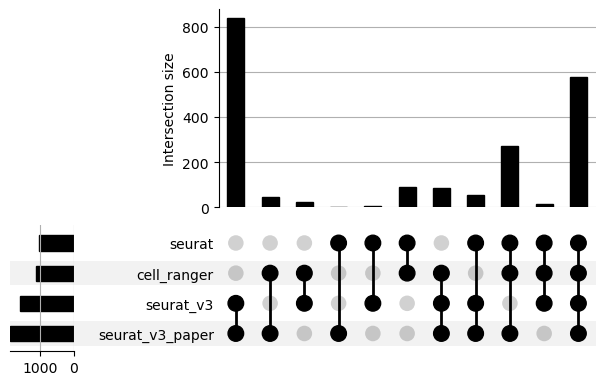

In [26]:
ax_dict = UpSet(result).plot()

### Data download and unpacking

In [9]:
!test -f 'GSE147729_RAW.tar' || \
    wget -O 'GSE147729_RAW.tar' 'https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE147729&format=file' && \
    echo "Import data and Select observarions whose ID starts with Lane1_"

Import data and Select observarions whose ID starts with Lane1_


In [10]:
!test -f 'GSM4443875_young_A_barcodes.tsv.gz' || \
    tar -xvf 'GSE147729_RAW.tar'

### Data loading

In [48]:
%%time
datasets = []
for idx in datasetsIds:
    datasets.append(createExperimentDataFrame(idx))

CPU times: user 7.45 s, sys: 758 ms, total: 8.21 s
Wall time: 4.05 s


In [78]:
result = pd.concat((young_A_df, young_B_df))

In [79]:
result.shape, young_A_df.shape, young_B_df.shape

((57384, 7749), (28692, 5431), (28692, 2337))

In [25]:
result = df

In [26]:
result.fillna(0, inplace=True)

In [27]:
result = result.apply(pd.to_numeric, downcast='integer')

In [82]:
mask = result.isna()

In [88]:
young_A_df.index

Index(['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Rp1', 'Sox17', 'Gm37323', 'Mrpl15',
       'Lypla1', 'Gm37988',
       ...
       'AC125149.1', 'AC125149.2', 'AC125149.4', 'AC234645.1', 'AC168977.2',
       'AC168977.1', 'PISD', 'DHRSX', 'Vmn2r122', 'CAAA01147332.1'],
      dtype='object', length=28692)

In [87]:
result[~mask]

,AAACCTGAGTTCGATC-1,AAACCTGCAATCGGTT-1,AAACCTGCACACGCTG-1,AAACCTGCACGGATAG-1,AAACCTGCATCATCCC-1,AAACCTGCATCTACGA-1,AAACCTGCATTCACTT-1,AAACCTGGTATAGTAG-1,AAACCTGGTGACTCAT-1,AAACCTGGTTACGACT-1,...,TTTCCTCTCGATGAGG-1,TTTGCGCCATCCTTGC-1,TTTGCGCGTCGCATCG-1,TTTGCGCTCCAAGTAC-1,TTTGGTTCAGACAGGT-1,TTTGGTTGTTAGATGA-1,TTTGGTTGTTCCGTCT-1,TTTGGTTTCTGCTGCT-1,TTTGTCAAGCGATATA-1,TTTGTCAAGCGTTGCC-1
Xkr4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gm1992,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gm37381,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rp1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rp1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC168977.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PISD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.0,2.0,2.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0
DHRSX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
Vmn2r122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
result.head()

,AAACCTGAGTTCGATC-1,AAACCTGCAATCGGTT-1,AAACCTGCACACGCTG-1,AAACCTGCACGGATAG-1,AAACCTGCATCATCCC-1,AAACCTGCATCTACGA-1,AAACCTGCATTCACTT-1,AAACCTGGTATAGTAG-1,AAACCTGGTGACTCAT-1,AAACCTGGTTACGACT-1,...,TTTGGTTGTCTAGGTT-1,TTTGGTTTCTACGAGT-1,TTTGTCAAGTCACGCC-1,TTTGTCACAAGGGTCA-1,TTTGTCAGTAGCCTAT-1,TTTGTCAGTCGGGTCT-1,TTTGTCAGTCTTCTCG-1,TTTGTCAGTGACTCAT-1,TTTGTCATCTATCCTA-1,TTTGTCATCTGCTTGC-1
Xkr4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Gm1992,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Gm37381,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Rp1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Rp1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [49]:
young_B_df.fillna(0, inplace=True)
young_B_df = young_B_df.apply(pd.to_numeric, downcast='integer')

In [57]:
young_B_df.to_csv("GSM4443875_young_B_merged.tsv", sep="\t")

In [29]:
result.to_csv("GSM4443875_merged.tsv", sep="\t")

In [50]:
results = zip(datasetsIds, datasets)
#map(lambda x: x[1].to_csv(x[0] + "merged.tsv", sep="\t"), list(results))

In [51]:
for (idx, df) in results:
    df.to_csv(idx + "merged.tsv", sep="\t")

In [43]:
len(list(results))

0

### Data inspection

In [58]:
_in_dir = path(".").resolve()
_publish_dir = path(".").resolve()
if not _publish_dir.exists():
    _publish_dir.mkdir()
print(f"Reading data from: {_in_dir.name}")
print(f"Saving processed data to: {_publish_dir.name}")

Reading data from: boolai
Saving processed data to: boolai


In [31]:
infile = _in_dir /'GSM4443875_merged.tsv'
outfile = _publish_dir / "GSM4443875_merged.csv"

### Comparing data with hematopoiesis results

In [109]:
df = pd.read_csv('sc_metadata.csv')

In [110]:
df

,Unnamed: 0,barcode,age,sampleName,phases,G1_score,G2M_score,S_score,AGE,numclust,...,TMC,HEM,CAM,HLOD,MHC,AgingSvendsen,hscScore,Pseudotime,Monocle_state,HSPC_state
0,young_B_AAACCTGCATACTCTT-1,AAACCTGCATACTCTT-1,2_months,young_B,G1/G0,0.971,0.033,0.462,Young,ifn,...,-0.074905,0.073133,-0.226138,0.249831,0.016209,-0.102484,0.442611,3.962058,1.0,ifnHSC
1,young_B_AAACCTGTCATGGTCA-1,AAACCTGTCATGGTCA-1,2_months,young_B,S,0.126,0.077,0.637,Young,div,...,-0.316274,-0.172426,-0.023335,0.065557,0.291425,-0.258633,0.003176,12.342092,5.0,NaN
2,young_B_AAACGGGCACAGAGGT-1,AAACGGGCACAGAGGT-1,2_months,young_B,G1/G0,0.878,0.082,0.269,Young,np3,...,0.159012,0.073540,0.086192,0.019260,0.235743,0.027833,0.461091,1.822380,1.0,iHSC
3,young_B_AAACGGGCACCAGGCT-1,AAACGGGCACCAGGCT-1,2_months,young_B,G1/G0,0.855,0.002,0.616,Young,rep,...,-0.348279,-0.199399,-0.162716,0.069128,-0.299042,-0.202788,0.059569,18.348021,5.0,NaN
4,young_B_AAACGGGCAGCCTATA-1,AAACGGGCAGCCTATA-1,2_months,young_B,G1/G0,0.866,0.277,0.357,Young,np3,...,0.336349,0.083644,-0.099730,-0.385274,-0.292880,0.025087,0.436824,4.516276,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14910,old_A_TTTGTCAAGTGGCACA-1,TTTGTCAAGTGGCACA-1,17_months,aged_A,G1/G0,0.979,0.017,0.768,Aged,diff,...,0.210463,0.388134,0.521194,-0.121709,0.752729,0.088144,0.436179,4.142474,1.0,preDiff
14911,old_A_TTTGTCACACGAAACG-1,TTTGTCACACGAAACG-1,17_months,aged_A,G1/G0,0.798,0.007,0.176,Aged,ifn,...,0.550251,0.496008,0.512288,-0.022671,0.732978,0.197133,0.438580,1.922991,1.0,ifnHSC
14912,old_A_TTTGTCAGTACGAAAT-1,TTTGTCAGTACGAAAT-1,17_months,aged_A,G1/G0,1.000,0.000,0.011,Aged,rep,...,0.546974,0.196677,0.117432,-0.315677,-0.073736,0.085435,0.238523,17.799680,5.0,NaN
14913,old_A_TTTGTCAGTATAGTAG-1,TTTGTCAGTATAGTAG-1,17_months,aged_A,G1/G0,0.913,0.076,0.360,Aged,np4,...,0.625405,0.332465,0.639392,-0.094833,0.397015,0.189295,0.353279,1.994134,1.0,iHSC


### Read in data

In [59]:
infile = _in_dir / 'GSM4443875_young_B_merged.tsv'

In [60]:
%%time 
adata = st.read(file_name=infile.as_posix(), workdir='./stream_result')

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Saving results in: ./stream_result
CPU times: user 11.7 s, sys: 157 ms, total: 11.9 s
Wall time: 11.8 s


In [61]:
adata.obs_names_make_unique()
adata.var_names_make_unique()

In [62]:
adata

AnnData object with n_obs × n_vars = 2337 × 28692 
    uns: 'workdir'

### Calculate QC

In [91]:
st.cal_qc(adata,assay='rna')

NameError: name 'st' is not defined

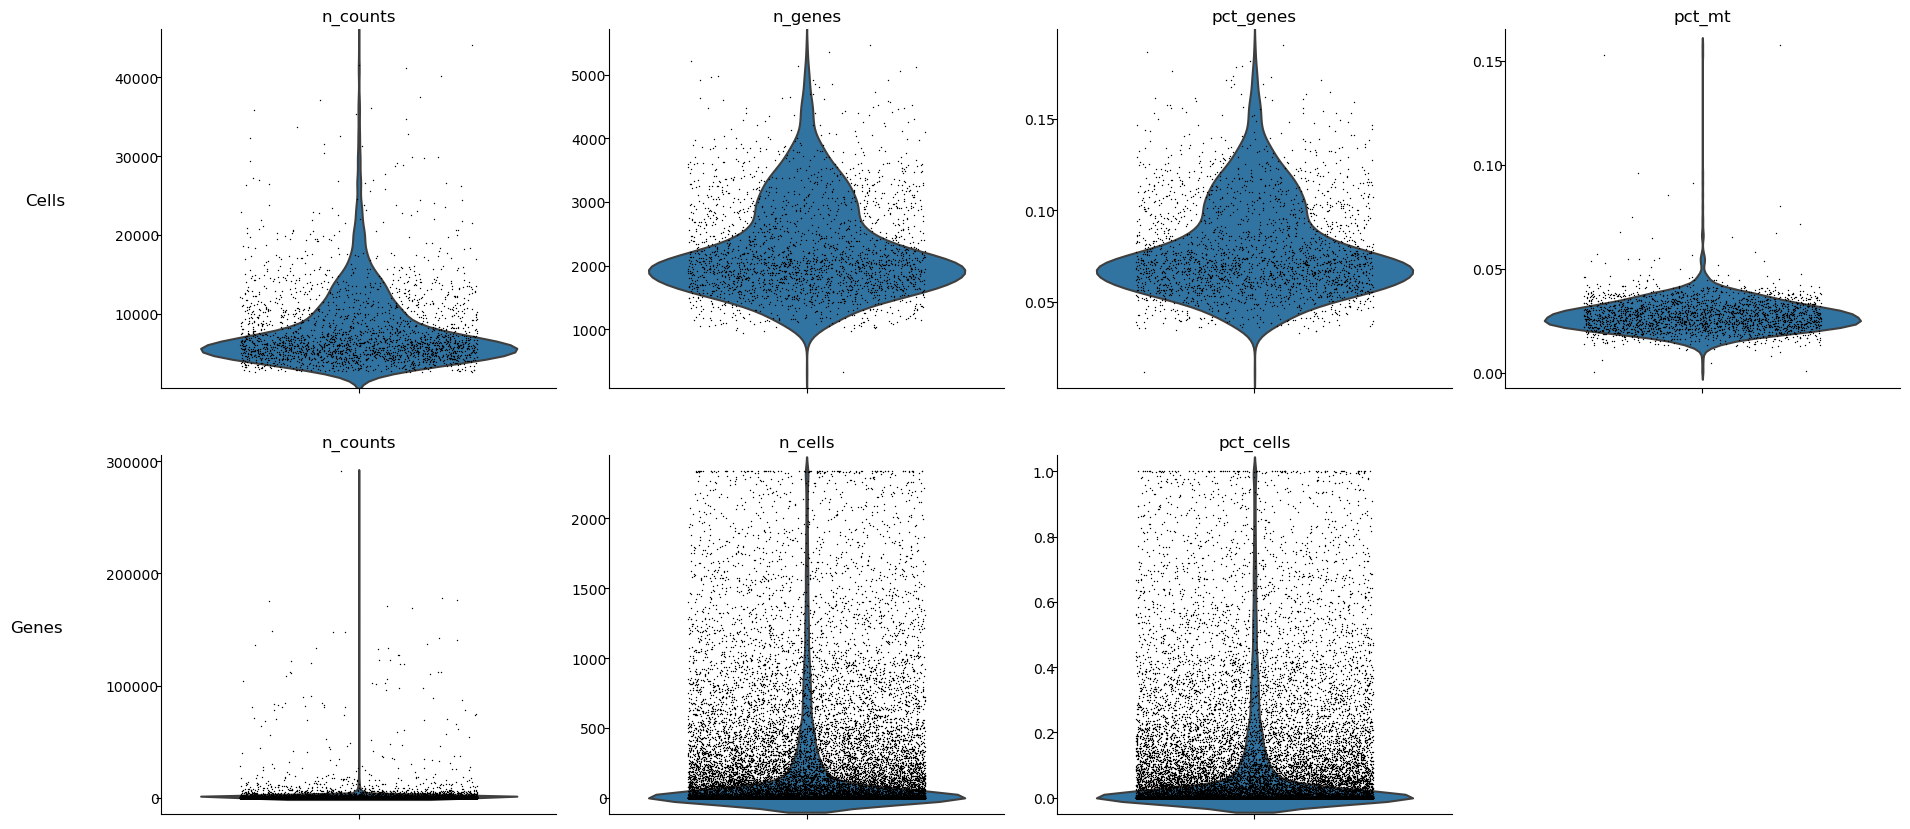

In [64]:
st.plot_qc(adata,jitter=0.3,)

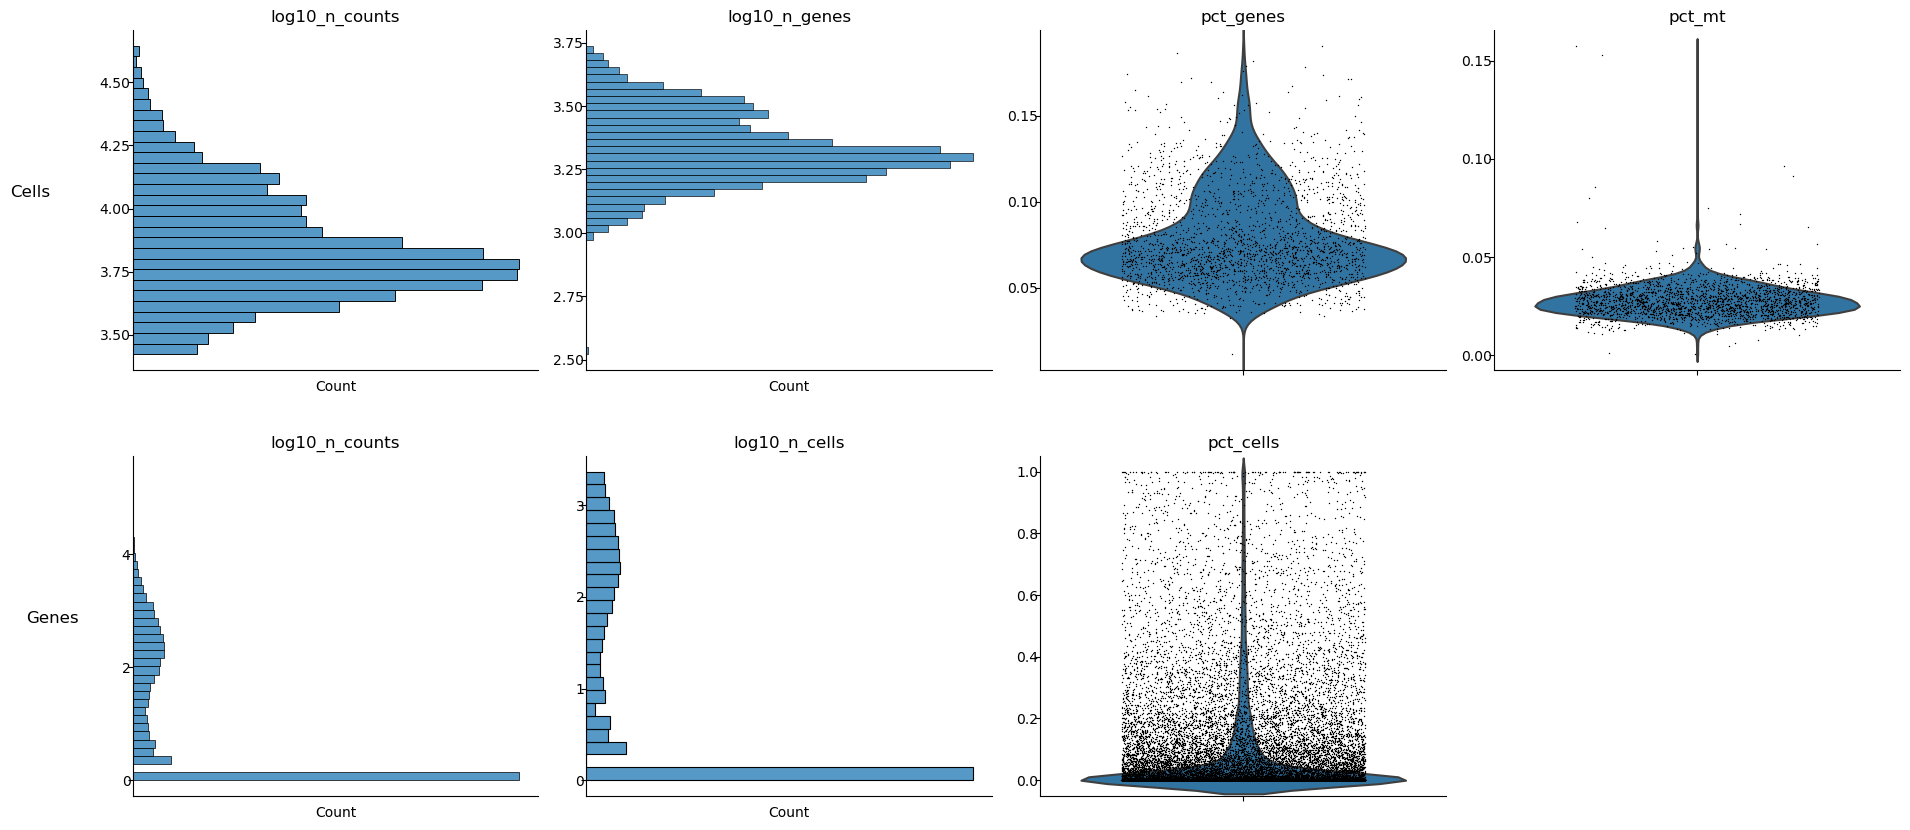

In [65]:
### histogram plots and log-scale are also supported
st.plot_qc(adata,jitter=0.3,log_scale=[0,1,4,5],hist_plot=[0,1,4,5]) 

In [66]:
# From the article
st.filter_cells(adata, min_n_features=200)
st.filter_features(adata, min_n_cells =3)

filter cells based on min_n_features


/home/jasiek/miniconda3/envs/stream/lib/python3.7/site-packages/anndata/core/anndata.py:1239: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_categorical(df_full[k]):


after filtering out low-quality cells: 
2337 cells, 28692 genes
Filter genes based on min_n_cells
After filtering out low-expressed genes: 
2337 cells, 14287 genes


In [67]:
###Normalize gene expression based on library size  
st.normalize(adata,method='lib_size')
###Logarithmize gene expression 
st.log_transform(adata)
###Remove mitochondrial genes 
st.remove_mt_genes(adata)

remove mitochondrial genes:
['mt-Nd1', 'mt-Nd2', 'mt-Co1', 'mt-Co2', 'mt-Atp8', 'mt-Atp6', 'mt-Co3', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb']


### Feature selection

770 variable genes are selected
CPU times: user 2.33 s, sys: 744 ms, total: 3.07 s
Wall time: 5.12 s


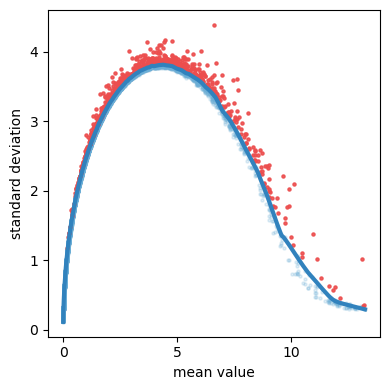

In [46]:
%%time
st.select_variable_genes(adata,loess_frac=0.005) 
# The number of variable genes is set to 1_648 because it was the number of genes kept in the original article's analyses

714 variable genes are selected
CPU times: user 2.03 s, sys: 962 ms, total: 2.99 s
Wall time: 4.77 s


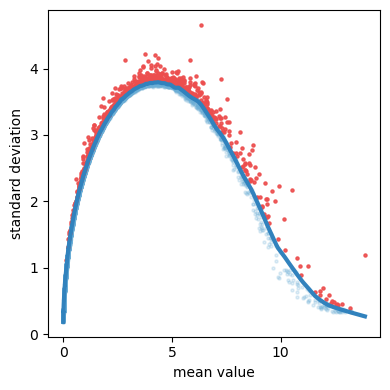

In [68]:
%%time
st.select_variable_genes(adata,loess_frac=0.005) 

In [105]:
marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
len(marker_genes)

NameError: name 'it' is not defined

# SCANPY

In [ ]:
scanpy.experimental.pp.highly_variable_genes

In [57]:
for idx in datasetsIds:
    batch_id = "_".join(idx.split("_")[1:3])
    print(batch_id)

young_A
young_B
old_A
old_B


In [58]:
datasets_adata = []

for idx in datasetsIds:
    batch_id = "_".join(idx.split("_")[1:3])
    adata = sc.read_csv(idx + "merged.tsv", delimiter="\t")
    adata = adata.T
    adata.obs_names_make_unique()
    adata.var_names_make_unique()
    adata.obs['batch'] = batch_id
    datasets_adata.append(adata)

/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jan.malinowski/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/jan.malinowski/anaconda3/envs/sc

In [59]:
adata

AnnData object with n_obs × n_vars = 4331 × 28692
    obs: 'batch'

In [60]:
datasets_adata[0].obs.head()

,batch
AAACCTGAGTTCGATC-1,young_A
AAACCTGCAATCGGTT-1,young_A
AAACCTGCACACGCTG-1,young_A
AAACCTGCACGGATAG-1,young_A
AAACCTGCATCATCCC-1,young_A


In [61]:
merged_adata = createMergedDataset(datasetsIds, datasets_adata)

In [24]:
adata.obs['batch'].head()

AAACCTGCATTTGCCC-1    old_B
AAACCTGGTACCCAAT-1    old_B
AAACCTGGTCAAACTC-1    old_B
AAACCTGGTCCGAATT-1    old_B
AAACCTGGTCTTGTCC-1    old_B
Name: batch, dtype: object

In [84]:
adata.var.head()

,n_cells,mt,highly_variable,means,dispersions,dispersions_norm,highly_variable_nbatches,highly_variable_intersection
Mrpl15,8160,False,False,0.571273,0.268214,0.138539,1,False
Lypla1,3448,False,False,0.211658,-0.017419,-0.303339,0,False
Tcea1,6916,False,False,0.477075,0.068212,-0.376338,0,False
Gm16041,11,False,False,0.000714,-0.092113,-0.327428,0,False
Atp6v1h,3341,False,False,0.206798,-0.057332,-0.380992,0,False


In [28]:
#adata = common_preprocessing(adata)

In [86]:
results = hvg_scanpy(adata, method="seurat")

In [96]:
results.rename(columns={'highly_variable':'test'})

,means,dispersions,dispersions_norm,test,highly_variable_nbatches,highly_variable_intersection
0610007P14Rik,0.380706,-0.774633,-0.542946,False,0,False
0610009B22Rik,0.232553,-0.645925,-0.391664,False,0,False
0610009L18Rik,0.092736,-0.494567,-0.287048,False,0,False
0610009O20Rik,0.118020,-0.499735,-0.222509,False,0,False
0610010F05Rik,0.043499,-0.437640,-0.183848,False,0,False
...,...,...,...,...,...,...
mt-Nd3,0.466429,-0.864650,-0.384540,False,0,False
mt-Nd4,1.095663,-2.383065,-0.991078,False,0,False
mt-Nd4l,0.252010,-0.582584,0.246719,False,1,False
mt-Nd5,0.479608,-0.936861,-0.615138,False,0,False


In [66]:
# From the article
st.filter_cells(adata, min_n_features=200)
st.filter_features(adata, min_n_cells =3)

filter cells based on min_n_features


/home/jasiek/miniconda3/envs/stream/lib/python3.7/site-packages/anndata/core/anndata.py:1239: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_categorical(df_full[k]):


after filtering out low-quality cells: 
2337 cells, 28692 genes
Filter genes based on min_n_cells
After filtering out low-expressed genes: 
2337 cells, 14287 genes


In [67]:
###Normalize gene expression based on library size  
st.normalize(adata,method='lib_size')
###Logarithmize gene expression 
st.log_transform(adata)
###Remove mitochondrial genes 
st.remove_mt_genes(adata)

remove mitochondrial genes:
['mt-Nd1', 'mt-Nd2', 'mt-Co1', 'mt-Co2', 'mt-Atp8', 'mt-Atp6', 'mt-Co3', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb']


In [ ]:
# Teraz Twoja macierz 'adata.obs' zawiera kolumnę 'batch' z wartościami 'young_A' i 'young_B'
print(adata.obs.head())

# 3. Standardowy preprocessing przed HVG
sc.pp.normalize_total(adata, target_sum=1e4)

# 4. KLUCZOWY MOMENT: Selekcja HVG z parametrem batch_key
# Dzięki temu Scanpy wyliczy HVG dla każdej myszy osobno i wybierze te wspólne
# UWAGA: Metoda Pearsona WYMAGA surowych zliczeń (integer counts)
# Nie logarytmuj danych przed tą funkcją!

In [ ]:


# Teraz możesz podejrzeć, które geny zostały wybrane
print(adata.var.head())

In [55]:
print(ad.__version__)

0.12.10


/tmp/ipykernel_7823/3757652304.py:1: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(ad.__version__)


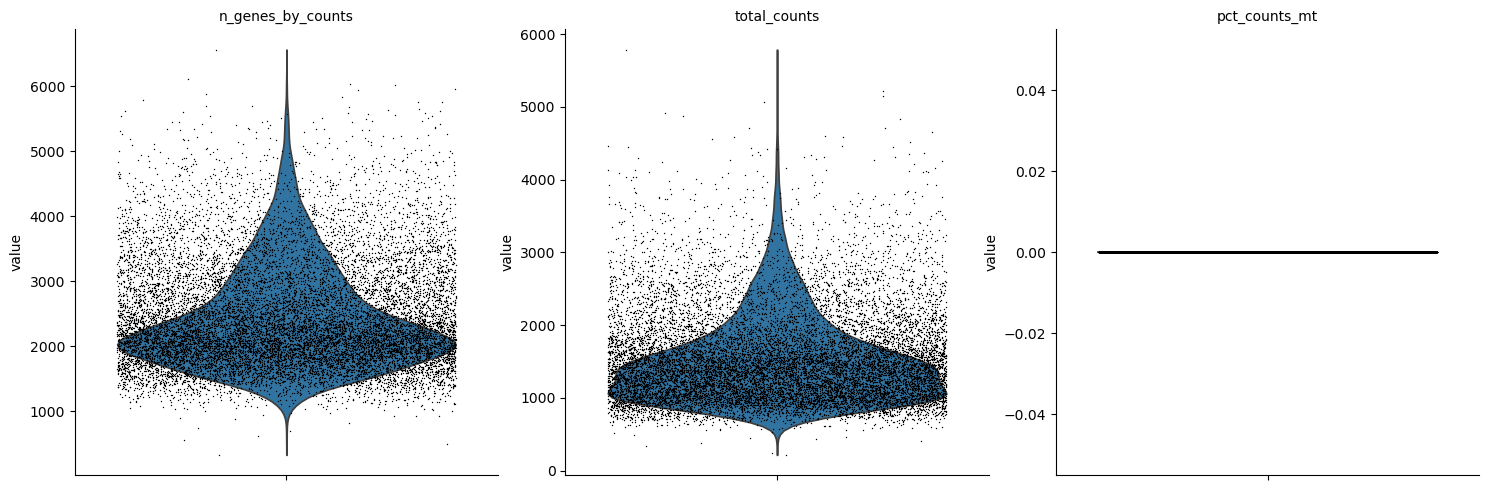

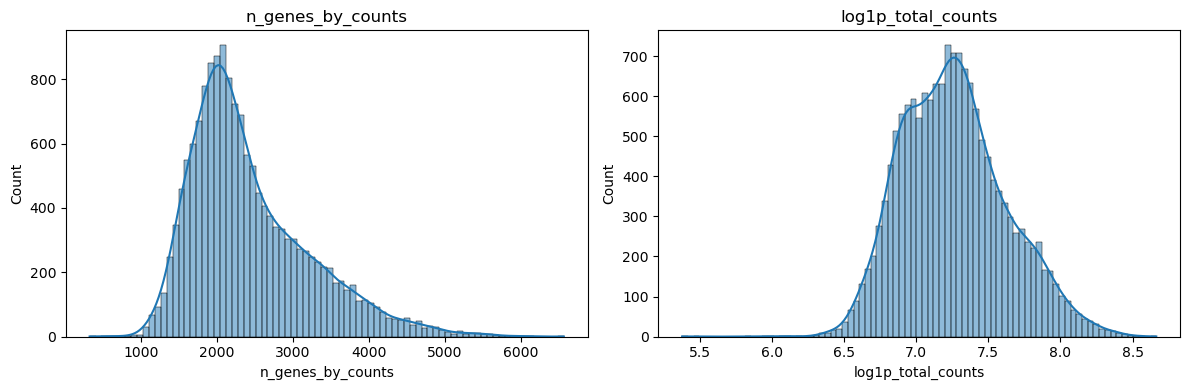

In [94]:
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Przygotowanie metryk (odpowiednik st.cal_qc)
adata.var['mt'] = adata.var_names.str.startswith('MT-') 
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=True, inplace=True)

# 2. Odpowiednik st.plot_qc(jitter=0.3)
# To działa bez zmian w Scanpy
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], 
             jitter=0.4, multi_panel=True)

# 3. Odpowiednik st.plot_qc(..., log_scale=..., hist_plot=...)
# Używamy seaborn.histplot dla pełnej kontroli
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Histogram dla n_genes
sns.histplot(adata.obs['n_genes_by_counts'], kde=True, ax=axs[0])
axs[0].set_title('n_genes_by_counts')

# Histogram dla total_counts w skali LOG (odpowiednik log_scale w STREAM)
# Używamy kolumny log1p_total_counts wygenerowanej przez calculate_qc_metrics
sns.histplot(adata.obs['log1p_total_counts'], kde=True, ax=axs[1])
axs[1].set_title('log1p_total_counts')

plt.tight_layout()
plt.show()